# Algebra
## 01 - Quadratische Gleichungen

Lösen von $ax^2 + bx + c = 0$ - Diskriminante $\Delta = b^2 - 4ac$, abc-Formel (Mitternachtsformel), quadratische Ergänzung, Satz von Vieta und biquadratische Gleichungen durch Substitution $u = x^2$.

> Vorausgesetzt: lineare Gleichungen, Äquivalenzumformungen.

### Lernziele

- Du kannst die **abc-Formel** (Mitternachtsformel) sicher anwenden.
- Du kennst die **Diskriminante** $\Delta = b^2 - 4ac$ und weißt, was sie über die Lösungsanzahl aussagt.
- Du beherrschst die **quadratische Ergänzung** als Lösungstechnik.
- Du kennst den **Satz von Vieta** und kannst ihn zur Probe und zum Lösen nutzen.
- Du kannst **biquadratische Gleichungen** durch Substitution auf quadratische zurückführen.

---

## 1. Grundfrom der quadratische Gleichung

Eine **quadratische Gleichung** hat die allgemeine Form:

$$
ax^2 + bx + c = 0, \quad a \neq 0
$$

Dabei heißt $a$ der **Leitkoeffizient**, $b$ der **lineare Koeffizient** und $c$ das **Absolutglied**.

**Sonderfall Reinform** ($b = 0$): $\quad ax^2 + c = 0 \implies x^2 = -\frac{c}{a}$

$$
x^2 = 9 \implies x = \pm 3 \qquad\qquad x^2 = -4 \implies \text{keine reelle Lösung}
$$

**Sonderfall** ($c = 0$): $\quad ax^2 + bx = 0 \implies x(ax + b) = 0$

$$
x_1 = 0 \quad \text{oder} \quad x_2 = -\frac{b}{a}
$$

> **Merke:** Teile nie durch $x$ - damit verliert man die Lösung $x = 0$. Immer ausklammern!

## 2. Die Diskriminante

Die **Diskriminante** $\Delta$ (griech. Delta) ist definiert als:

$$
\Delta = b^2 - 4ac
$$

Das Vorzeichen von $\Delta$ entscheidet, wie viele reelle Lösungen existieren - und damit auch, ob überhaupt eine Lösung gefunden werden kann. 

Ein negatives $\Delta$ bedeutet: keine reelle Lösung, alle weitere Rechnung erübrigt sich. Die geometrische Bedeutung (Parabel und x-Achse) wird klarer, wenn wir in Kapitel **Funktionen** die Parabel als Graph betrachten.

| Diskriminante | Anzahl der Lösungen | Bedeutung |
|---|---|---|
| $\Delta > 0$ | 2 verschiedene reelle Lösungen | Parabel schneidet x-Achse zweimal |
| $\Delta = 0$ | 1 Lösung (doppelte Nullstelle) | Parabel berührt x-Achse |
| $\Delta < 0$ | keine reelle Lösung | Parabel schneidet x-Achse nicht |

**Beispiele:**

$$
x^2 - 5x + 6 = 0: \quad \Delta = 25 - 24 = 1 > 0 \quad \Rightarrow \text{zwei Lösungen}
$$
$$
x^2 - 4x + 4 = 0: \quad \Delta = 16 - 16 = 0 \quad \Rightarrow \text{eine Lösung}
$$
$$
x^2 + x + 1 = 0: \quad \Delta = 1 - 4 = -3 < 0 \quad \Rightarrow \text{keine reelle Lösung}
$$

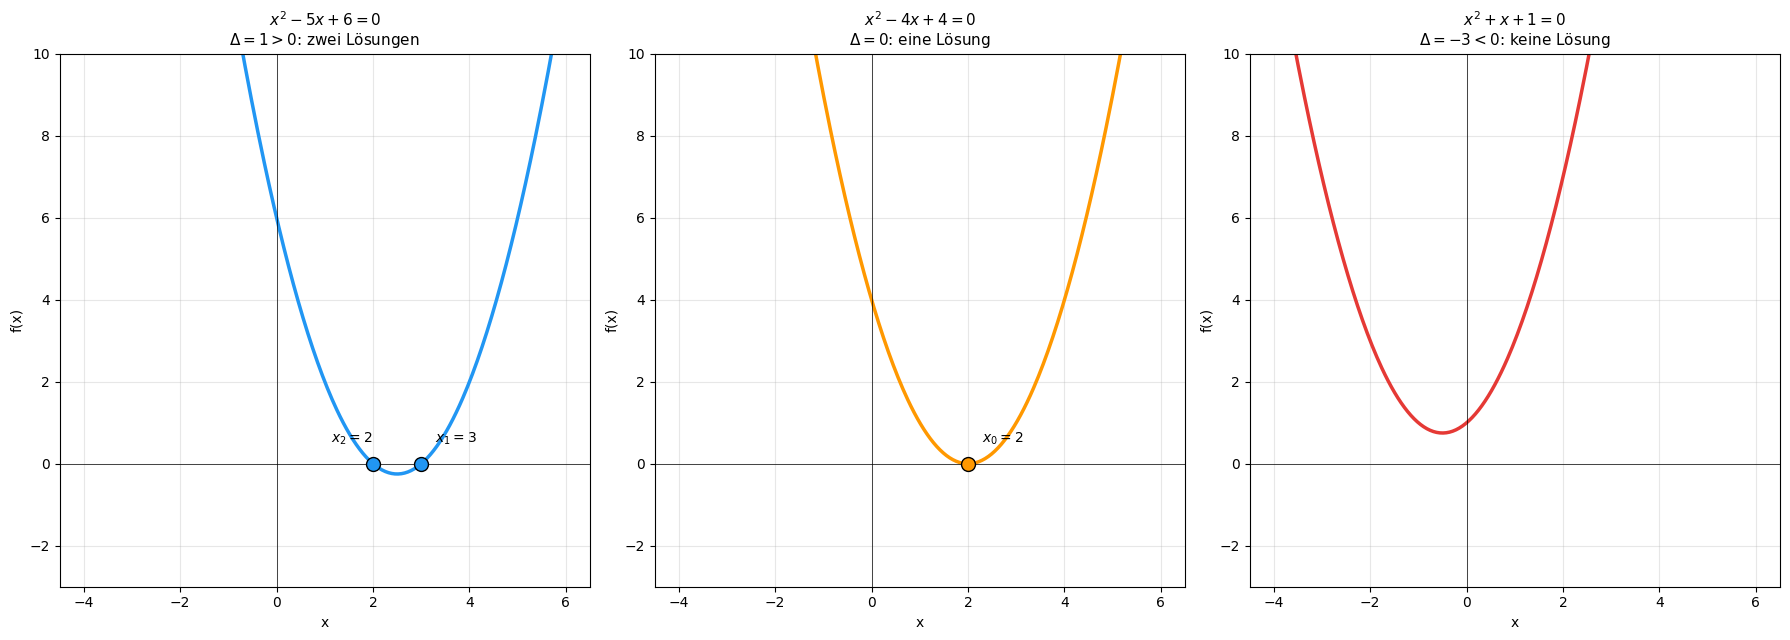

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# --- Visualisierung: Die drei Fälle der Diskriminante ---

def visualisiere_diskriminante():
    """Zeigt drei Parabeln: Δ > 0 (zwei Nullstellen), Δ = 0 (eine), Δ < 0 (keine)."""
    fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
    x = np.linspace(-4, 6, 300)

    # Drei Beispiele aus dem Text
    beispiele = [
        (1, -5, 6,  r"$x^2 - 5x + 6 = 0$" + "\n" + r"$\Delta = 1 > 0$: zwei Lösungen"),
        (1, -4, 4,  r"$x^2 - 4x + 4 = 0$" + "\n" + r"$\Delta = 0$: eine Lösung"),
        (1,  1, 1,  r"$x^2 + x + 1 = 0$" + "\n" + r"$\Delta = -3 < 0$: keine Lösung"),
    ]
    farben = ["#2196F3", "#FF9800", "#E53935"]

    for ax, (a, b, c, titel), farbe in zip(axes, beispiele, farben):
        y = a * x**2 + b * x + c
        ax.plot(x, y, color=farbe, linewidth=2.5)
        ax.axhline(0, color='black', linewidth=0.5)
        ax.axvline(0, color='black', linewidth=0.5)
        ax.grid(True, alpha=0.3)
        ax.set_title(titel, fontsize=11)
        ax.set_xlabel("x")
        ax.set_ylabel("f(x)")
        ax.set_ylim(-3, 10)

        # Nullstellen markieren
        delta = b**2 - 4*a*c
        if delta > 0:
            x1 = (-b + np.sqrt(delta)) / (2*a)
            x2 = (-b - np.sqrt(delta)) / (2*a)
            ax.scatter([x1, x2], [0, 0], color=farbe, s=100, zorder=5, edgecolors='black')
            ax.annotate(f"$x_1 = {x1:.0f}$", (x1, 0), textcoords="offset points",
                        xytext=(10, 15), fontsize=10)
            ax.annotate(f"$x_2 = {x2:.0f}$", (x2, 0), textcoords="offset points",
                        xytext=(-30, 15), fontsize=10)
        elif delta == 0:
            x0 = -b / (2*a)
            ax.scatter([x0], [0], color=farbe, s=100, zorder=5, edgecolors='black')
            ax.annotate(f"$x_0 = {x0:.0f}$", (x0, 0), textcoords="offset points",
                        xytext=(10, 15), fontsize=10)

    plt.tight_layout()
    plt.show()

visualisiere_diskriminante()

## 3. Die abc-Formel (Mitternachtsformel)

Für $ax^2 + bx + c = 0$ gilt:

$$
\boxed{x_{1,2} = \frac{-b \pm \sqrt{b^2 - 4ac}}{2a}}
$$

Sie heißt **Mitternachtsformel**, weil man sie auch um Mitternacht auswendig wissen sollte (das ist wirklich der Grund).

**Beispiel 1:** $\quad 2x^2 - 5x - 3 = 0$

$$
\Delta = (-5)^2 - 4 \cdot 2 \cdot (-3) = 25 + 24 = 49
$$
$$
x_{1,2} = \frac{5 \pm \sqrt{49}}{4} = \frac{5 \pm 7}{4}
\implies x_1 = \frac{12}{4} = 3, \quad x_2 = \frac{-2}{4} = -\frac{1}{2}
$$

**Probe:** $\quad 2(3)^2 - 5(3) - 3 = 18 - 15 - 3 = 0$ ✓ $\quad$ und $\quad 2(-\tfrac{1}{2})^2 - 5(-\tfrac{1}{2}) - 3 = \tfrac{1}{2} + \tfrac{5}{2} - 3 = 0$ ✓

**Beispiel 2:** $\quad x^2 - 6x + 9 = 0$

$$
\Delta = 36 - 36 = 0 \implies x_{1,2} = \frac{6}{2} = 3 \quad \text{(doppelte Nullstelle)}
$$

**Sonderfall pq-Formel** (wenn $a = 1$): $\quad x^2 + px + q = 0$

$$
x_{1,2} = -\frac{p}{2} \pm \sqrt{\left(\frac{p}{2}\right)^2 - q}
$$

**Beispiel:** $\quad x^2 - 5x + 6 = 0 \implies x_{1,2} = \frac{5}{2} \pm \sqrt{\frac{25}{4} - 6} = \frac{5}{2} \pm \frac{1}{2} \implies x_1 = 3,\ x_2 = 2$

## 4. Quadratische Ergänzung als Lösungstechnik

Die **quadratische Ergänzung** ist eine alternative Lösungsmethode und liefert automatisch den Rechenweg zur abc-Formel. Außerdem ist sie die Grundlage der Scheitelpunktform (→ Kapitel **Funktionen**).

**Idee:** Forme $ax^2 + bx + c = 0$ so um, dass links ein vollständiges Quadrat steht, dann ziehe die Wurzel.

**Rezept für $a = 1$:** $\quad x^2 + px + q = 0$

$$
x^2 + px = -q \qquad\text{(Konstanten nach rechts bringen)}
$$
$$
x^2 + px + \left(\frac{p}{2}\right)^2 = -q + \left(\frac{p}{2}\right)^2 \qquad\text{(quadratische Ergänzung: $\left(\frac{p}{2}\right)^2$ auf beiden Seiten)}
$$
$$
\left(x + \frac{p}{2}\right)^2 = \left(\frac{p}{2}\right)^2 - q \qquad\text{(linke Seite als vollständiges Quadrat schreiben)}
$$
$$
x + \frac{p}{2} = \pm\sqrt{\left(\frac{p}{2}\right)^2 - q} \;\Longrightarrow\; x_{1,2} = -\frac{p}{2} \pm \sqrt{\left(\frac{p}{2}\right)^2 - q} \qquad\text{(Wurzel ziehen, nach $x$ auflösen)}
$$

**Beispiel:** $\quad x^2 + 6x + 5 = 0$

$$
x^2 + 6x = -5 \qquad\text{(Konstanten $+5$ nach rechts)}
$$
$$
x^2 + 6x + 9 = -5 + 9 = 4 \qquad\text{(Ergänzung: $(6/2)^2 = 9$)}
$$
$$
(x + 3)^2 = 4 \;\Longrightarrow\; x + 3 = \pm 2 \;\Longrightarrow\; x_1 = -1,\; x_2 = -5 \qquad\text{(Wurzel $\to$ zwei Lösungen)}
$$

**Beispiel mit $a \neq 1$:** $\quad 3x^2 - 12x + 9 = 0$

Zunächst durch $a = 3$ dividieren: $\quad x^2 - 4x + 3 = 0$

$$
x^2 - 4x = -3 \qquad\text{(Konstanten nach rechts)}
$$
$$
(x - 2)^2 = -3 + 4 = 1 \;\Longrightarrow\; x - 2 = \pm 1 \;\Longrightarrow\; x_1 = 3,\; x_2 = 1 \qquad\text{(Ergänzung $(4/2)^2 = 4$, dann Wurzel)}
$$

> **Merke:** Ergänze immer den Term $\left(\frac{p}{2}\right)^2$ auf **beiden Seiten** der Gleichung.

## 5. Satz von Vieta

Der Satz von Vieta stellt eine direkte Beziehung zwischen den Lösungen einer Gleichung und ihren Koeffizienten her - ohne dass man die Lösungen selbst berechnet haben muss. 

Das kann zur schnellen Probe, aber auch zum Lösen von Gleichungen durch Raten genutzt werden.

Sind $x_1$ und $x_2$ die Lösungen von $x^2 + px + q = 0$, dann gilt:

$$
\boxed{x_1 + x_2 = -p \qquad x_1 \cdot x_2 = q}
$$

Für die allgemeine Form $ax^2 + bx + c = 0$:

$$
x_1 + x_2 = -\frac{b}{a} \qquad x_1 \cdot x_2 = \frac{c}{a}
$$

**Herleitung:** Wenn $x_1, x_2$ die Nullstellen sind, dann lässt sich das Polynom faktorisieren:

$$
x^2 + px + q = (x - x_1)(x - x_2) = x^2 - (x_1 + x_2)x + x_1 x_2
$$

Koeffizientenvergleich liefert $x_1 + x_2 = -p$ und $x_1 x_2 = q$.

**Anwendung - Lösen durch Raten:** Bei $x^2 + px + q = 0$ suche zwei Zahlen, deren **Summe** $-p$ und deren **Produkt** $q$ ist.

**Beispiel:** $\quad x^2 - 7x + 12 = 0$

Gesucht: $x_1 + x_2 = 7$ und $x_1 \cdot x_2 = 12 \implies$ Kandidaten: $3$ und $4$ ✓

$$
\implies x_1 = 3, \quad x_2 = 4
$$

**Probe mit Vieta:** $\quad 3 + 4 = 7 = -(-7)$ ✓ $\quad$ und $\quad 3 \cdot 4 = 12$ ✓

> **Merke:** Vieta eignet sich perfekt als schnelle **Probe** nach der abc-Formel. Einfach Summe und Produkt der Lösungen nachrechnen.

## 6. Biquadratische Gleichungen (Substitution)

Eine **biquadratische Gleichung** hat die Form:

$$
ax^4 + bx^2 + c = 0, \quad a \neq 0
$$

**Lösungsstrategie:** Substitution $u = x^2$ reduziert sie auf eine quadratische Gleichung in $u$:

$$
au^2 + bu + c = 0
$$

**Vorgehen:**

1. Substituiere $u = x^2$, löse die quadratische Gleichung in $u$.
2. Rücksubstitution: $x^2 = u_i \implies x = \pm\sqrt{u_i}$ (nur wenn $u_i \geq 0$!)
3. Negative $u_i$ liefern keine reellen Lösungen.

**Beispiel:** $\quad x^4 - 5x^2 + 4 = 0$

**Schritt 1:** Substitution $u = x^2$:

$$
u^2 - 5u + 4 = 0 \implies (u - 1)(u - 4) = 0 \implies u_1 = 1, \quad u_2 = 4
$$

**Schritt 2:** Rücksubstitution:

$$
x^2 = 1 \implies x_{1,2} = \pm 1 \qquad x^2 = 4 \implies x_{3,4} = \pm 2
$$

**Beispiel mit negativer Teillösung:** $\quad x^4 - 3x^2 - 4 = 0$

$$
u^2 - 3u - 4 = 0 \implies u_1 = 4, \quad u_2 = -1
$$

$u_2 = -1 < 0$ → keine reellen Lösungen daraus. Nur $u_1 = 4$ liefert $x = \pm 2$.

> **Merke:** Die Substitution $u = x^2$ funktioniert immer dann, wenn nur gerade Potenzen von $x$ auftreten.

In [2]:
import math

def abc_formel(a, b, c):
    """Löst ax² + bx + c = 0 mit der abc-Formel."""
    delta = b**2 - 4*a*c
    if delta > 0:
        x1 = (-b + math.sqrt(delta)) / (2*a)
        x2 = (-b - math.sqrt(delta)) / (2*a)
        return x1, x2
    elif delta == 0:
        x = -b / (2*a)
        return (x,)  # doppelte Nullstelle
    else:
        return ()  # keine reelle Lösung

def vieta_probe(a, b, c, loesungen):
    """Prüft die Lösungen mit dem Satz von Vieta."""
    if len(loesungen) == 2:
        x1, x2 = loesungen
        summe_soll = -b / a
        produkt_soll = c / a
        summe_ist = x1 + x2
        produkt_ist = x1 * x2
        ok_s = abs(summe_ist - summe_soll) < 1e-9
        ok_p = abs(produkt_ist - produkt_soll) < 1e-9
        return ok_s and ok_p
    return True

# --- Verifikation ---
print("=" * 55)
print("Verifikation: abc-Formel & Vieta")
print("=" * 55)

beispiele = [
    (2, -5, -3, "2x² - 5x - 3 = 0"),
    (1, -6,  9, "x² - 6x + 9 = 0  (doppelte NST)"),
    (1,  1,  1, "x² + x + 1 = 0  (keine reelle Lsg)"),
    (1, -7, 12, "x² - 7x + 12 = 0"),
]

for a, b, c, bezeichnung in beispiele:
    delta = b**2 - 4*a*c
    loesungen = abc_formel(a, b, c)
    print(f"\n  {bezeichnung}")
    print(f"  Δ = {b}² - 4·{a}·{c} = {delta}")
    if len(loesungen) == 2:
        x1, x2 = loesungen
        vieta_ok = vieta_probe(a, b, c, loesungen)
        print(f"  x₁ = {x1:g},  x₂ = {x2:g}")
        print(f"  Vieta-Probe: x₁+x₂ = {x1+x2:g} (soll {-b/a:g}), "
              f"x₁·x₂ = {x1*x2:g} (soll {c/a:g})  {'✓' if vieta_ok else '✗'}")
    elif len(loesungen) == 1:
        print(f"  x₁₂ = {loesungen[0]:g}  (doppelte Nullstelle)")
    else:
        print("  Keine reelle Lösung (Δ < 0)")

# --- Biquadratische Gleichung ---
print("\n" + "=" * 55)
print("Verifikation: Biquadratische Gleichungen")
print("=" * 55)

def biquadratisch(a, b, c, bezeichnung):
    """Löst ax⁴ + bx² + c = 0 durch Substitution u = x²."""
    print(f"\n  {bezeichnung}")
    u_loesungen = abc_formel(a, b, c)  # u² statt x²
    x_loesungen = []
    for u in u_loesungen:
        if u >= 0:
            x_loesungen += [math.sqrt(u), -math.sqrt(u)]
        else:
            print(f"  u = {u:g} < 0 → verwirft (keine reelle Lsg.)")
    x_loesungen = sorted(set(round(x, 10) for x in x_loesungen))
    print(f"  Lösungen: x = {[f'{x:g}' for x in x_loesungen]}")

biquadratisch(1, -5,  4, "x⁴ - 5x² + 4 = 0")
biquadratisch(1, -3, -4, "x⁴ - 3x² - 4 = 0")

Verifikation: abc-Formel & Vieta

  2x² - 5x - 3 = 0
  Δ = -5² - 4·2·-3 = 49
  x₁ = 3,  x₂ = -0.5
  Vieta-Probe: x₁+x₂ = 2.5 (soll 2.5), x₁·x₂ = -1.5 (soll -1.5)  ✓

  x² - 6x + 9 = 0  (doppelte NST)
  Δ = -6² - 4·1·9 = 0
  x₁₂ = 3  (doppelte Nullstelle)

  x² + x + 1 = 0  (keine reelle Lsg)
  Δ = 1² - 4·1·1 = -3
  Keine reelle Lösung (Δ < 0)

  x² - 7x + 12 = 0
  Δ = -7² - 4·1·12 = 1
  x₁ = 4,  x₂ = 3
  Vieta-Probe: x₁+x₂ = 7 (soll 7), x₁·x₂ = 12 (soll 12)  ✓

Verifikation: Biquadratische Gleichungen

  x⁴ - 5x² + 4 = 0
  Lösungen: x = ['-2', '-1', '1', '2']

  x⁴ - 3x² - 4 = 0
  u = -1 < 0 → verwirft (keine reelle Lsg.)
  Lösungen: x = ['-2', '2']


---

## Verständnis-Check

#### Aufgabe 1: abc-Formel

Löse mit der abc-Formel und gib die Diskriminante an:

a) $x^2 - 7x + 10 = 0$

b) $3x^2 + 6x + 3 = 0$

c) $2x^2 + 3x + 5 = 0$

d) $x^2 - 2x - 8 = 0$

#### Aufgabe 2: Quadratische Ergänzung

Löse durch quadratische Ergänzung (ohne abc-Formel):

a) $x^2 + 8x + 12 = 0$

b) $x^2 - 4x - 5 = 0$

c) $2x^2 + 12x + 10 = 0$

#### Aufgabe 3: Satz von Vieta

a) Finde die Lösungen von $x^2 - 9x + 20 = 0$ durch Raten (Vieta).

b) Eine quadratische Gleichung mit $a = 1$ hat die Lösungen $x_1 = -3$ und $x_2 = 5$. Bestimme die Gleichung.

c) Prüfe mit Vieta: Sind $x_1 = \frac{1}{2}$ und $x_2 = -3$ Lösungen von $2x^2 + 5x - 3 = 0$?

#### Aufgabe 4: Biquadratische Gleichungen

a) $x^4 - 13x^2 + 36 = 0$

b) $x^4 - 10x^2 + 9 = 0$

c) $x^4 + 2x^2 - 3 = 0$

### Lösungen

<details><summary>Lösung Aufgabe 1: abc-Formel</summary>

a) $x^2 - 7x + 10 = 0$: $\Delta = 49 - 40 = 9 > 0 \implies x_{1,2} = \frac{7 \pm 3}{2} \implies x_1 = 5,\ x_2 = 2$

b) $3x^2 + 6x + 3 = 0$: $\Delta = 36 - 36 = 0 \implies x_{1,2} = \frac{-6}{6} = -1$ (doppelte Nullstelle)

c) $2x^2 + 3x + 5 = 0$: $\Delta = 9 - 40 = -31 < 0 \implies$ **keine reelle Lösung**

d) $x^2 - 2x - 8 = 0$: $\Delta = 4 + 32 = 36 \implies x_{1,2} = \frac{2 \pm 6}{2} \implies x_1 = 4,\ x_2 = -2$

</details>

<details><summary>Lösung Aufgabe 2: Quadratische Ergänzung</summary>

a) $x^2 + 8x + 12 = 0 \implies x^2 + 8x = -12 \implies (x+4)^2 = 4 \implies x + 4 = \pm 2 \implies x_1 = -2,\ x_2 = -6$

b) $x^2 - 4x - 5 = 0 \implies (x-2)^2 = 9 \implies x - 2 = \pm 3 \implies x_1 = 5,\ x_2 = -1$

c) Erst durch $2$ dividieren: $x^2 + 6x + 5 = 0 \implies (x+3)^2 = 4 \implies x_1 = -1,\ x_2 = -5$

</details>

<details><summary>Lösung Aufgabe 3: Satz von Vieta</summary>

a) $x_1 + x_2 = 9$, $x_1 \cdot x_2 = 20$ → $x_1 = 4,\ x_2 = 5$

b) Gleichung: $x^2 - (x_1 + x_2)x + x_1 x_2 = x^2 - 2x - 15 = 0$

c) $\frac{1}{2} + (-3) = -\frac{5}{2}$, Vieta erwartet $-\frac{b}{a} = -\frac{5}{2}$ ✓; $\frac{1}{2} \cdot (-3) = -\frac{3}{2}$, Vieta erwartet $\frac{c}{a} = -\frac{3}{2}$ ✓ → **Ja, korrekte Lösungen**.

</details>

<details><summary>Lösung Aufgabe 4: Biquadratische Gleichungen</summary>

a) $u^2 - 13u + 36 = 0 \implies u_1 = 9,\ u_2 = 4 \implies x = \pm 3$ oder $x = \pm 2$

b) $u^2 - 10u + 9 = 0 \implies u_1 = 9,\ u_2 = 1 \implies x = \pm 3$ oder $x = \pm 1$

c) $u^2 + 2u - 3 = 0 \implies u_1 = 1,\ u_2 = -3$. Da $u_2 < 0$: nur $x^2 = 1 \implies x = \pm 1$

</details>

---

## Zusammenfassung

| Konzept | Kernaussage |
|---------|-------------|
| Grundform | $ax^2 + bx + c = 0$, Sonderfälle bei $b=0$ oder $c=0$ |
| Diskriminante | $\Delta = b^2 - 4ac$ bestimmt Anzahl reeller Lösungen |
| abc-Formel | $x_{1,2} = \frac{-b \pm \sqrt{\Delta}}{2a}$ - universelle Lösungsformel |
| Quadratische Ergänzung | Umformung zum vollständigen Quadrat, Basis der Scheitelpunktform |
| Satz von Vieta | $x_1 + x_2 = -\frac{b}{a}$, $x_1 \cdot x_2 = \frac{c}{a}$ - ideal für Probe und Raten |
| Biquadratische Gleichungen | Substitution $u = x^2$ reduziert $ax^4 + bx^2 + c = 0$ auf Quadratische |

---

## Glossar

| Deutsch | English |
|---------|---------|
| Quadratische Gleichung | Quadratic equation |
| Leitkoeffizient | Leading coefficient |
| Diskriminante | Discriminant |
| Mitternachtsformel / abc-Formel | Quadratic formula |
| pq-Formel | pq-formula |
| Quadratische Ergänzung | Completing the square |
| Doppelte Nullstelle | Double root / repeated root |
| Nullstelle | Root / zero |
| Satz von Vieta | Vieta's formulas |
| Biquadratische Gleichung | Biquadratic equation |
| Substitution | Substitution |
| Rücksubstitution | Back-substitution |
| Probe | Verification / check |